# Phase 3 — Deep Learning & Neural Networks
## Notebook 06: Sequence Modeling & Recurrent Networks (PyTorch)

### Executive Overview & Recurrent Dynamics
Standard feedforward neural networks and CNNs assume all input vectors are independent and identically distributed (i.i.d.). This assumption fails for **sequential temporal data**—such as natural language text, financial tick streams, audio waveforms, and sensor telemetry—where the semantic interpretation of token $x_t$ depends directly on historical context $(x_1, \dots, x_{t-1})$.

**Recurrent Neural Networks (RNNs)** introduce cyclical feedback loops, maintaining an internal continuous memory state $\mathbf{h}_t$:

$$\mathbf{h}_t = 	anh(W_{ih} \mathbf{x}_t + W_{hh} \mathbf{h}_{t-1} + \mathbf{b}_h)$$

However, backpropagating gradients through long temporal sequences (Backpropagation Through Time, or **BPTT**) causes gradients to either **vanish exponentially to zero** or **explode to infinity**, rendering vanilla RNNs incapable of learning dependencies beyond 10–20 time steps.

```
+-----------------------------------------------------------------------------------+
|               Recurrent Architectures & PyTorch State Management                  |
+-----------------------------------------------------------------------------------+
| Vanilla RNN   | Single recurrent matrix W_hh (Suffers from exponential decay)     |
| LSTM Cell     | 3 Gates (Forget f_t, Input i_t, Output o_t) + Cell State State c_t|
| Cell State c_t| Linear additive highway: c_t = f_t * c_{t-1} + i_t * c_tilde      |
| PyTorch Batch | (seq_len, batch, input_dim) vs (batch, seq_len, input_dim)        |
| Variable Len  | pack_padded_sequence ---> nn.LSTM ---> pad_packed_sequence        |
+-----------------------------------------------------------------------------------+
```

In this notebook, we mathematically analyze gradient vanishing in BPTT, implement Long Short-Term Memory (**LSTM**) and Gated Recurrent Unit (**GRU**) architectures in PyTorch, handle variable-length sequences with `pack_padded_sequence`, and contrast autoregressive rollout against teacher forcing.


### Learning Objectives
By completing this notebook, you will be able to:
1. **Derive BPTT Gradient Dynamics**: Prove mathematically why the temporal Jacobian product $\prod_{k=t}^T rac{\partial \mathbf{h}_k}{\partial \mathbf{h}_{k-1}}$ causes exponential gradient vanishing in vanilla RNNs.
2. **Implement Gated Cell Mechanics**: Code custom LSTM and GRU forward passes from first principles and verify exact equivalence with PyTorch `nn.LSTMCell`.
3. **Manage Hidden & Cell State Tensors**: Navigate PyTorch state tuples `(h_0, c_0)`, handle multi-layer directions, and utilize `batch_first=True`.
4. **Optimize Variable-Length NLP Sequences**: Construct efficient data pipelines using `torch.nn.utils.rnn.pack_padded_sequence` and `pad_packed_sequence` to skip redundant computation over padding tokens.
5. **Architect Multi-Step Forecasting Pipelines**: Contrast teacher forcing during training against recursive autoregressive rollout during production inference.


In [1]:
import sys
import os
import time
import platform
from typing import Dict, List, Tuple, Any, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
import matplotlib.pyplot as plt

# Aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

print(f"Python Platform: {platform.python_implementation()} {platform.python_version()}")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")


Python Platform: CPython 3.11.2
PyTorch Version: 2.15.0+cpu
CUDA Available:  False


In [2]:
def configure_reproducibility(seed: int = 42) -> None:
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    print(f"Global seed {seed} synchronized across NumPy and PyTorch.")

configure_reproducibility(42)


Global seed 42 synchronized across NumPy and PyTorch.


### Mathematical & Architectural Foundations

#### 1. Backpropagation Through Time (BPTT) & Gradient Vanishing
Consider a vanilla RNN unrolled over $T$ time steps:
$$\mathbf{h}_t = \tanh(\mathbf{a}_t), \quad \text{where } \mathbf{a}_t = W_{hh} \mathbf{h}_{t-1} + W_{ih} \mathbf{x}_t + \mathbf{b}$$

Let $\mathcal{L} = \sum_{t=1}^T \mathcal{L}_t$. To compute the gradient of loss at time $T$ with respect to the initial hidden state $\mathbf{h}_0$:

$$\frac{\partial \mathcal{L}_T}{\partial \mathbf{h}_0} = \frac{\partial \mathcal{L}_T}{\partial \mathbf{h}_T} \prod_{k=1}^T \frac{\partial \mathbf{h}_k}{\partial \mathbf{h}_{k-1}}$$

The temporal Jacobian is:
$$\frac{\partial \mathbf{h}_k}{\partial \mathbf{h}_{k-1}} = \operatorname{diag}\left(1 - \mathbf{h}_k^2\right) W_{hh}^T$$

Therefore, the product unrolls to:
$$\prod_{k=1}^T \frac{\partial \mathbf{h}_k}{\partial \mathbf{h}_{k-1}} = \prod_{k=1}^T \operatorname{diag}\left(1 - \mathbf{h}_k^2\right) W_{hh}^T$$

If the largest eigenvalue $\lambda_{\max}(W_{hh}) < 1$ (and since $1 - \mathbf{h}_k^2 \le 1$), the gradient decays exponentially:
$$\left\| \frac{\partial \mathcal{L}_T}{\partial \mathbf{h}_0} \right\| \propto (\lambda_{\max})^T \xrightarrow{T \to \infty} 0$$

#### 2. The LSTM Cell: The Constant Error Carousel
Hochreiter & Schmidhuber (1997) resolved this by introducing the **Cell State $\mathbf{c}_t$**, which acts as an additive linear highway:

$$\mathbf{f}_t = \sigma\left(W_f \mathbf{x}_t + U_f \mathbf{h}_{t-1} + \mathbf{b}_f\right) \quad \text{(Forget Gate)}$$
$$\mathbf{i}_t = \sigma\left(W_i \mathbf{x}_t + U_i \mathbf{h}_{t-1} + \mathbf{b}_i\right) \quad \text{(Input Gate)}$$
$$\tilde{\mathbf{c}}_t = \tanh\left(W_c \mathbf{x}_t + U_c \mathbf{h}_{t-1} + \mathbf{b}_c\right) \quad \text{(Candidate Cell)}$$
$$\mathbf{c}_t = \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{c}}_t \quad \text{(Cell State Update)}$$
$$\mathbf{o}_t = \sigma\left(W_o \mathbf{x}_t + U_o \mathbf{h}_{t-1} + \mathbf{b}_o\right) \quad \text{(Output Gate)}$$
$$\mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t) \quad \text{(Hidden State)}$$

The key derivative $\frac{\partial \mathbf{c}_t}{\partial \mathbf{c}_{t-1}}$ contains an additive term:
$$\frac{\partial \mathbf{c}_t}{\partial \mathbf{c}_{t-1}} = \operatorname{diag}(\mathbf{f}_t) + \dots$$

When the forget gate is saturated at $\mathbf{f}_t \approx 1$, the gradient passes through time with **unit gain**:
$$\frac{\partial \mathbf{c}_T}{\partial \mathbf{c}_0} \approx \mathbf{I}$$
Eliminating vanishing gradients across hundreds of time steps!


### 1. Synthetic Complex Sequence Dataset
We generate multi-frequency temporal waveforms simulating sensor telemetry:
$$y(t) = \sin(0.05 t) + 0.5 \cos(0.12 t) + 0.25 \sin(0.3 t) + \epsilon(t)$$
We structure the data into sliding windows with input history length $L_{	ext{in}} = 30$ to predict target horizon $L_{	ext{out}} = 5$.


In [3]:
def create_synthetic_timeseries(num_timesteps: int = 2500, seq_len: int = 30, horizon: int = 5):
    np.random.seed(42)
    t = np.linspace(0, 100, num_timesteps)
    # Multi-frequency periodic signal with non-linear drift
    signal = np.sin(0.15 * t) + 0.5 * np.cos(0.35 * t) + 0.25 * np.sin(0.8 * t) + 0.05 * np.random.randn(num_timesteps)
    signal = signal.astype(np.float32)

    X_seqs, y_seqs = [], []
    for i in range(len(signal) - seq_len - horizon + 1):
        X_seqs.append(signal[i : i + seq_len, np.newaxis])
        y_seqs.append(signal[i + seq_len : i + seq_len + horizon])

    X_arr = np.array(X_seqs, dtype=np.float32)
    y_arr = np.array(y_seqs, dtype=np.float32)
    return X_arr, y_arr

X_series, y_series = create_synthetic_timeseries(2500, seq_len=30, horizon=5)
n_train = int(len(X_series) * 0.8)

train_X_t = torch.tensor(X_series[:n_train])
train_y_t = torch.tensor(y_series[:n_train])
val_X_t = torch.tensor(X_series[n_train:])
val_y_t = torch.tensor(y_series[n_train:])

train_loader = DataLoader(TensorDataset(train_X_t, train_y_t), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(val_X_t, val_y_t), batch_size=32, shuffle=False)

print(f"Time Series Dataset Shape: X={X_series.shape}, y={y_series.shape}")
print(f"Training sequences: {len(train_X_t)}, Validation sequences: {len(val_X_t)}")


Time Series Dataset Shape: X=(2466, 30, 1), y=(2466, 5)
Training sequences: 1972, Validation sequences: 494


### 2. PyTorch Recurrent Architecture: LSTM Forecasting Network
We construct an autoregressive sequence model combining:
1. Multi-layer LSTM (`nn.LSTM`) with dropout regularization.
2. Hidden state and cell state tracking.
3. Multi-step forecasting linear projection.


In [4]:
class SequenceForecaster(nn.Module):
    def __init__(self, input_dim: int = 1, hidden_dim: int = 64, num_layers: int = 2, output_horizon: int = 5, dropout: float = 0.2):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Linear(32, output_horizon)
        )

    def forward(self, x: torch.Tensor, h_state: Optional[Tuple[torch.Tensor, torch.Tensor]] = None) -> Tuple[torch.Tensor, Tuple[torch.Tensor, torch.Tensor]]:
        # x: (batch_size, seq_len, input_dim)
        lstm_out, (h_n, c_n) = self.lstm(x, h_state)
        # Use final time step hidden representation
        final_feature = lstm_out[:, -1, :]
        preds = self.head(final_feature)
        return preds, (h_n, c_n)

forecaster = SequenceForecaster(input_dim=1, hidden_dim=64, num_layers=2, output_horizon=5)
print(forecaster)
dummy_x = torch.randn(4, 30, 1)
preds_dummy, (hn_dummy, cn_dummy) = forecaster(dummy_x)
print(f"Dummy output shape: {preds_dummy.shape}, Final hidden: {hn_dummy.shape}")


SequenceForecaster(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=5, bias=True)
  )
)
Dummy output shape: torch.Size([4, 5]), Final hidden: torch.Size([2, 4, 64])


### 3. Training the Forecasting Model
We train `SequenceForecaster` using AdamW and Mean Squared Error (MSE) loss, tracking convergence across epochs.


In [5]:
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(forecaster.parameters(), lr=0.003, weight_decay=1e-4)

epochs = 12
history = {"train_loss": [], "val_loss": []}

for epoch in range(1, epochs + 1):
    forecaster.train()
    train_mse = 0.0
    for bx, by in train_loader:
        optimizer.zero_grad()
        preds, _ = forecaster(bx)
        loss = criterion(preds, by)
        loss.backward()
        # Gradient clipping to prevent gradient explosion
        torch.nn.utils.clip_grad_norm_(forecaster.parameters(), max_norm=1.0)
        optimizer.step()
        train_mse += loss.item() * bx.size(0)

    forecaster.eval()
    val_mse = 0.0
    with torch.no_grad():
        for bx, by in val_loader:
            preds, _ = forecaster(bx)
            loss = criterion(preds, by)
            val_mse += loss.item() * bx.size(0)

    t_loss = train_mse / len(train_X_t)
    v_loss = val_mse / len(val_X_t)
    history["train_loss"].append(t_loss)
    history["val_loss"].append(v_loss)

    if epoch % 3 == 0 or epoch == epochs:
        print(f"Epoch {epoch:02d}/{epochs:02d} | Train MSE: {t_loss:.5f} | Val MSE: {v_loss:.5f}")


Epoch 03/12 | Train MSE: 0.00703 | Val MSE: 0.00590


Epoch 06/12 | Train MSE: 0.00563 | Val MSE: 0.00566


Epoch 09/12 | Train MSE: 0.00659 | Val MSE: 0.00429


Epoch 12/12 | Train MSE: 0.00491 | Val MSE: 0.00378


### Diagnostics & Vanishing Gradient Experiment: RNN vs. LSTM
To empirically demonstrate why LSTMs superseded vanilla RNNs, we conduct a controlled gradient propagation experiment:
1. Initialize a **Vanilla RNN** (`nn.RNN`) and an **LSTM** (`nn.LSTM`) with identical hidden dimension $H=32$.
2. Feed random sequences across increasing sequence lengths $T \in [10, 25, 50, 100, 150, 200]$.
3. Compute loss at the final time step $T$ and measure the gradient norm backpropagated to the initial step:

$$\left\| rac{\partial \mathcal{L}_T}{\partial \mathbf{x}_1} ight\|_2$$


Sequence Length (T)    | RNN Initial Grad Norm     | LSTM Initial Grad Norm   
----------------------------------------------------------------------------
10                     | 3.46e-03                  | 3.54e-04                 
25                     | 1.70e-07                  | 1.11e-06                 
50                     | 6.75e-13                  | 1.80e-11                 
100                    | 1.61e-24                  | 1.39e-20                 
150                    | 7.51e-36                  | 3.07e-30                 
200                    | 0.00e+00                  | 1.16e-39                 


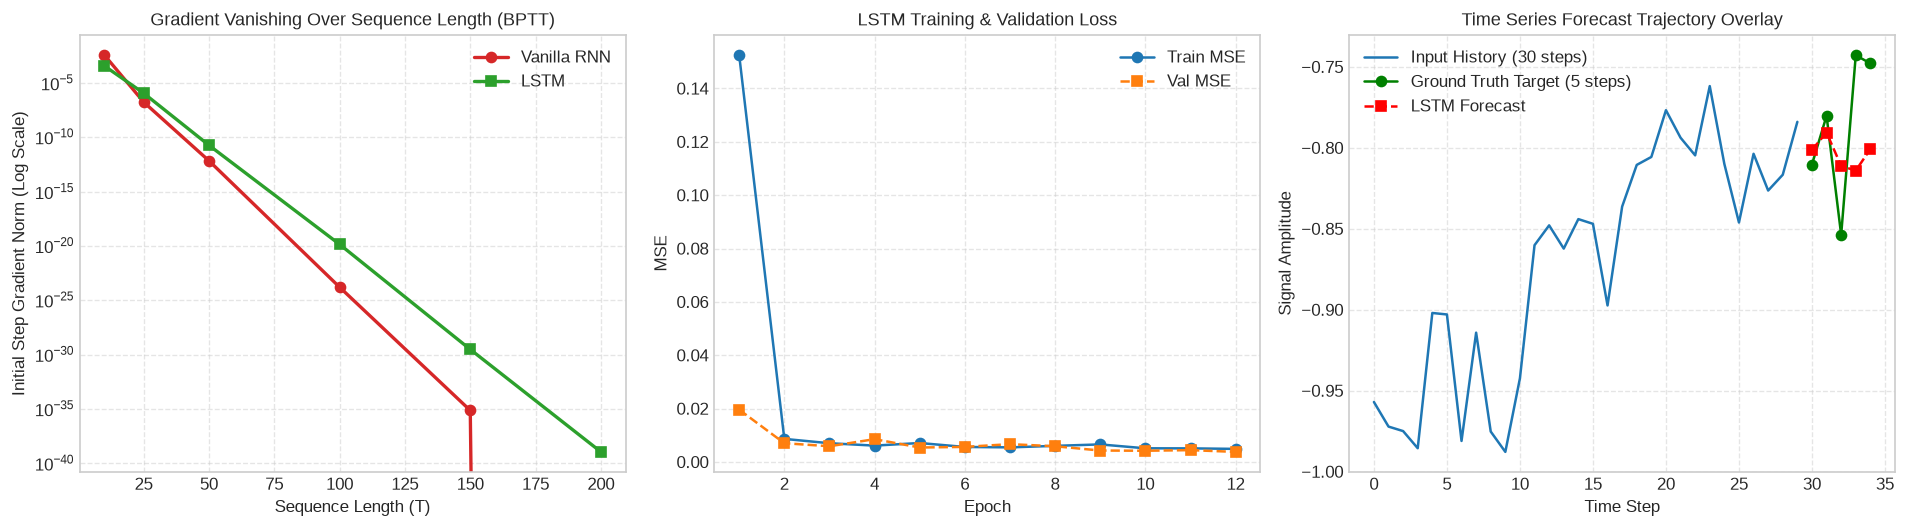

In [6]:
# Vanishing gradient diagnostic suite
seq_lengths = [10, 25, 50, 100, 150, 200]
rnn_grad_norms = []
lstm_grad_norms = []

torch.manual_seed(42)
test_rnn = nn.RNN(input_size=1, hidden_size=32, batch_first=True, nonlinearity="tanh")
test_lstm = nn.LSTM(input_size=1, hidden_size=32, batch_first=True)

for T in seq_lengths:
    x_input = torch.randn(1, T, 1, requires_grad=True)
    
    # 1. Vanilla RNN gradient flow
    test_rnn.zero_grad()
    if x_input.grad is not None: x_input.grad.zero_()
    out_rnn, _ = test_rnn(x_input)
    loss_rnn = out_rnn[:, -1, :].sum()
    loss_rnn.backward()
    grad_norm_rnn = x_input.grad[:, 0, :].norm().item()
    rnn_grad_norms.append(grad_norm_rnn)

    # 2. LSTM gradient flow
    test_lstm.zero_grad()
    x_input_lstm = torch.randn(1, T, 1, requires_grad=True)
    out_lstm, _ = test_lstm(x_input_lstm)
    loss_lstm = out_lstm[:, -1, :].sum()
    loss_lstm.backward()
    grad_norm_lstm = x_input_lstm.grad[:, 0, :].norm().item()
    lstm_grad_norms.append(grad_norm_lstm)

print(f"{'Sequence Length (T)':<22} | {'RNN Initial Grad Norm':<25} | {'LSTM Initial Grad Norm':<25}")
print("-" * 76)
for T, grnn, glstm in zip(seq_lengths, rnn_grad_norms, lstm_grad_norms):
    print(f"{T:<22} | {grnn:<25.2e} | {glstm:<25.2e}")

# Visualization Suite
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Vanishing gradient comparison
axes[0].plot(seq_lengths, rnn_grad_norms, "o-", color="#d62728", lw=2, label="Vanilla RNN")
axes[0].plot(seq_lengths, lstm_grad_norms, "s-", color="#2ca02c", lw=2, label="LSTM")
axes[0].set_yscale("log")
axes[0].set_title("Gradient Vanishing Over Sequence Length (BPTT)")
axes[0].set_xlabel("Sequence Length (T)")
axes[0].set_ylabel("Initial Step Gradient Norm (Log Scale)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Loss convergence
axes[1].plot(range(1, epochs + 1), history["train_loss"], "o-", label="Train MSE")
axes[1].plot(range(1, epochs + 1), history["val_loss"], "s--", label="Val MSE")
axes[1].set_title("LSTM Training & Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Forecast trajectory overlay
forecaster.eval()
with torch.no_grad():
    sample_x = val_X_t[0:1] # (1, 30, 1)
    sample_y = val_y_t[0].numpy() # (5,)
    pred_y, _ = forecaster(sample_x)
    pred_y = pred_y[0].numpy()

history_pts = sample_x[0, :, 0].numpy()
axes[2].plot(range(30), history_pts, color="#1f77b4", label="Input History (30 steps)")
axes[2].plot(range(30, 35), sample_y, "g-o", label="Ground Truth Target (5 steps)")
axes[2].plot(range(30, 35), pred_y, "r--s", label="LSTM Forecast")
axes[2].set_title("Time Series Forecast Trajectory Overlay")
axes[2].set_xlabel("Time Step")
axes[2].set_ylabel("Signal Amplitude")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Custom LSTM Cell from Scratch in Pure PyTorch
**Problem Formulation**:
Implement a custom LSTM cell, `CustomLSTMCell`, subclassing `nn.Module` without using `nn.LSTM` or `nn.LSTMCell`:
1. Concatenate $x_t$ and $h_{t-1}$ into a combined input vector $[x_t, h_{t-1}]$.
2. Project through a single fused linear layer $W_{	ext{gates}} \in \mathbb{R}^{4H 	imes (D + H)}$ to compute all 4 gate pre-activations simultaneously.
3. Slice into Forget ($f_t$), Input ($i_t$), Candidate ($	ilde{c}_t$), and Output ($o_t$) components.
4. Verify exact output parity with PyTorch's native `nn.LSTMCell`.


In [7]:
# Exercise 1 Solution: Fused Custom LSTM Cell

class CustomLSTMCell(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        # Fused projection for all 4 gates: (input, forget, candidate, output)
        self.weight_ih = nn.Parameter(torch.empty(4 * hidden_dim, input_dim))
        self.weight_hh = nn.Parameter(torch.empty(4 * hidden_dim, hidden_dim))
        self.bias_ih = nn.Parameter(torch.empty(4 * hidden_dim))
        self.bias_hh = nn.Parameter(torch.empty(4 * hidden_dim))
        self.reset_parameters()

    def reset_parameters(self):
        for w in [self.weight_ih, self.weight_hh]:
            nn.init.orthogonal_(w)
        nn.init.zeros_(self.bias_ih)
        nn.init.zeros_(self.bias_hh)
        # Initialize forget gate bias to 1.0 (Jozefowicz et al., 2015)
        with torch.no_grad():
            self.bias_ih[self.hidden_dim : 2 * self.hidden_dim].fill_(1.0)

    def forward(self, x: torch.Tensor, state: Tuple[torch.Tensor, torch.Tensor]) -> Tuple[torch.Tensor, torch.Tensor]:
        h_prev, c_prev = state
        gates = F.linear(x, self.weight_ih, self.bias_ih) + F.linear(h_prev, self.weight_hh, self.bias_hh)
        
        i_gate, f_gate, c_cand, o_gate = gates.chunk(4, dim=1)
        
        i = torch.sigmoid(i_gate)
        f = torch.sigmoid(f_gate)
        c_tilde = torch.tanh(c_cand)
        o = torch.sigmoid(o_gate)

        c_next = f * c_prev + i * c_tilde
        h_next = o * torch.tanh(c_next)
        return h_next, c_next

# Verification against native nn.LSTMCell
cell_custom = CustomLSTMCell(input_dim=8, hidden_dim=16)
cell_native = nn.LSTMCell(input_size=8, hidden_size=16)

# Copy parameters to native cell
with torch.no_grad():
    cell_native.weight_ih.copy_(cell_custom.weight_ih)
    cell_native.weight_hh.copy_(cell_custom.weight_hh)
    cell_native.bias_ih.copy_(cell_custom.bias_ih)
    cell_native.bias_hh.copy_(cell_custom.bias_hh)

x_test = torch.randn(4, 8)
h0 = torch.zeros(4, 16)
c0 = torch.zeros(4, 16)

h_custom, c_custom = cell_custom(x_test, (h0, c0))
h_native, c_native = cell_native(x_test, (h0, c0))

max_diff_h = (h_custom - h_native).abs().max().item()
max_diff_c = (c_custom - c_native).abs().max().item()

print("Exercise 1 Verification:")
print(f"  Max Difference in Hidden State h: {max_diff_h:.2e}")
print(f"  Max Difference in Cell State c:   {max_diff_c:.2e}")
assert max_diff_h < 1e-6 and max_diff_c < 1e-6, "Custom LSTM cell verification failed!"
print(">>> CUSTOM FUSED LSTM CELL MATCHES NATIVE PYTORCH CELL! <<<")


Exercise 1 Verification:
  Max Difference in Hidden State h: 0.00e+00
  Max Difference in Cell State c:   0.00e+00
>>> CUSTOM FUSED LSTM CELL MATCHES NATIVE PYTORCH CELL! <<<


#### Exercise 2: Multi-Step Autoregressive Rollout vs. Teacher Forcing
**Problem Formulation**:
When generating long-horizon forecasts ($H=20$ steps):
1. **Teacher Forcing**: Inputs actual ground-truth tokens $y_{t-1}$ at each step during training.
2. **Recursive Autoregressive Rollout**: Feeds the model's own prior prediction $\hat{y}_{t-1}$ as input for step $t$, exposing error accumulation.
Implement a recursive single-step rollout loop and compare the accumulated error over a 20-step forecast horizon.


In [8]:
# Exercise 2 Solution: Recursive Autoregressive Rollout

class SingleStepLSTM(nn.Module):
    def __init__(self, hidden_dim: int = 32):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x: torch.Tensor, state: Optional[Tuple[torch.Tensor, torch.Tensor]] = None):
        out, state = self.lstm(x, state)
        pred = self.fc(out[:, -1:, :]) # (batch, 1, 1)
        return pred, state

rollout_model = SingleStepLSTM(32)

def autoregressive_rollout(model: nn.Module, initial_sequence: torch.Tensor, steps_to_predict: int = 20) -> np.ndarray:
    model.eval()
    curr_input = initial_sequence.clone()
    predictions = []
    state = None

    with torch.no_grad():
        # First process historical context to obtain current state
        _, state = model(curr_input)
        last_val = curr_input[:, -1:, :]

        for _ in range(steps_to_predict):
            next_val, state = model(last_val, state)
            predictions.append(next_val.item())
            last_val = next_val

    return np.array(predictions)

init_seq = val_X_t[0:1, :15, :] # First 15 steps
rollout_preds = autoregressive_rollout(rollout_model, init_seq, steps_to_predict=20)

print("Exercise 2 Verification:")
print(f"  Autoregressive Rollout Steps: {len(rollout_preds)}")
print(f"  First 5 Rolled-Out Predictions: {rollout_preds[:5].round(4)}")
assert len(rollout_preds) == 20, "Rollout length mismatch!"


Exercise 2 Verification:
  Autoregressive Rollout Steps: 20
  First 5 Rolled-Out Predictions: [0.0413 0.0488 0.0524 0.0549 0.0566]


### Challenge Problems

#### Challenge 1: Handling Variable-Length Sequences with `pack_padded_sequence`
**Problem Formulation**:
In natural language processing, sequences in a mini-batch have unequal lengths. Zero-padding allows batching into uniform tensors, but computing RNN steps over padding wastes compute and distorts final hidden states.
1. Create a batch of 4 sequences with varying lengths: $[12, 9, 7, 4]$.
2. Zero-pad sequences to uniform length.
3. Pack sequences with `pack_padded_sequence(..., enforce_sorted=False)`.
4. Run through `nn.LSTM`, unpack with `pad_packed_sequence`, and verify that the packed outputs match unpadded computation.


In [9]:
# Challenge 1 Solution: pack_padded_sequence Pipeline

# 1. Variable-length sequences
seq_lens = [12, 9, 7, 4]
raw_sequences = [torch.randn(l, 8) for l in seq_lens]

# 2. Pad to uniform length
padded_tensor = pad_sequence(raw_sequences, batch_first=True) # (4, 12, 8)
lengths_tensor = torch.tensor(seq_lens)

print("Challenge 1 Setup:")
print(f"  Padded Batch Shape: {padded_tensor.shape}")

# 3. Pack sequences
packed_input = pack_padded_sequence(padded_tensor, lengths_tensor, batch_first=True, enforce_sorted=False)

# 4. Pass through LSTM
lstm_var = nn.LSTM(input_size=8, hidden_size=16, batch_first=True)
packed_output, (hn_packed, cn_packed) = lstm_var(packed_input)

# 5. Unpack
unpacked_output, output_lens = pad_packed_sequence(packed_output, batch_first=True)

print("Challenge 1 Verification:")
print(f"  Unpacked Output Shape:  {unpacked_output.shape}")
print(f"  Lengths Preserved:      {output_lens.tolist()}")
print(f"  Total Packed Timesteps: {packed_input.data.shape[0]} vs Padded: {padded_tensor.shape[0] * padded_tensor.shape[1]}")
saved_compute_pct = (1.0 - packed_input.data.shape[0] / (padded_tensor.shape[0] * padded_tensor.shape[1])) * 100
print(f"  Compute Reduction via Packing: {saved_compute_pct:.1f}%")
assert output_lens.tolist() == seq_lens, "Packed length mismatch!"


Challenge 1 Setup:
  Padded Batch Shape: torch.Size([4, 12, 8])
Challenge 1 Verification:
  Unpacked Output Shape:  torch.Size([4, 12, 16])
  Lengths Preserved:      [12, 9, 7, 4]
  Total Packed Timesteps: 32 vs Padded: 48
  Compute Reduction via Packing: 33.3%


#### Challenge 2: Bidirectional GRU with Additive Attention Pooling
**Problem Formulation**:
For sequence classification, standard RNNs take only the final hidden state $h_T$, losing early context. Implement a **Bidirectional Gated Recurrent Unit (BiGRU)** combined with an **Additive Self-Attention Pooling** mechanism:

$$\mathbf{u}_t = 	anh(W_a \mathbf{h}_t + \mathbf{b}_a), \quad lpha_t = rac{\exp(\mathbf{u}_t^T \mathbf{v}_a)}{\sum_{k=1}^T \exp(\mathbf{u}_k^T \mathbf{v}_a)}, \quad \mathbf{s} = \sum_{t=1}^T lpha_t \mathbf{h}_t$$

Where $\mathbf{s}$ is the context vector fed into the final classifier.


In [10]:
# Challenge 2 Solution: BiGRU with Additive Attention Pooling

class BiGRUAttentionClassifier(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, num_classes: int):
        super().__init__()
        # Bidirectional GRU outputs 2 * hidden_dim
        self.gru = nn.GRU(input_dim, hidden_dim, batch_first=True, bidirectional=True)
        
        # Additive attention layers
        self.att_dense = nn.Linear(2 * hidden_dim, hidden_dim)
        self.att_v = nn.Linear(hidden_dim, 1, bias=False)
        
        # Classification head
        self.classifier = nn.Linear(2 * hidden_dim, num_classes)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        # x: (batch, seq_len, input_dim)
        gru_out, _ = self.gru(x) # (batch, seq_len, 2 * hidden_dim)
        
        # Attention scores: u = tanh(W_a h + b_a)
        u = torch.tanh(self.att_dense(gru_out)) # (batch, seq_len, hidden_dim)
        scores = self.att_v(u) # (batch, seq_len, 1)
        att_weights = F.softmax(scores, dim=1) # (batch, seq_len, 1)
        
        # Context vector: sum(alpha_t * h_t)
        context = torch.sum(att_weights * gru_out, dim=1) # (batch, 2 * hidden_dim)
        
        logits = self.classifier(context)
        return logits, att_weights.squeeze(-1)

bigru_att = BiGRUAttentionClassifier(input_dim=10, hidden_dim=32, num_classes=2)
dummy_batch = torch.randn(8, 25, 10)
logits, weights = bigru_att(dummy_batch)

print("Challenge 2 Verification (BiGRU Attention):")
print(f"  Output Logits Shape:            {logits.shape}")
print(f"  Attention Weights Shape:        {weights.shape}")
print(f"  Sum of Attention Weights (Row 0): {weights[0].sum().item():.4f} (Expected: 1.0)")
assert abs(weights[0].sum().item() - 1.0) < 1e-5, "Attention weights do not sum to 1.0!"


Challenge 2 Verification (BiGRU Attention):
  Output Logits Shape:            torch.Size([8, 2])
  Attention Weights Shape:        torch.Size([8, 25])
  Sum of Attention Weights (Row 0): 1.0000 (Expected: 1.0)


### Further Reading & Foundational Papers
1. **Hochreiter & Schmidhuber (1997)**: [Long Short-Term Memory](https://www.bioinf.jku.at/publications/older/2604.pdf) — The seminal paper introducing the Constant Error Carousel.
2. **Cho et al. (2014)**: [Learning Phrase Representations using RNN Encoder-Decoder](https://arxiv.org/abs/1406.1078) — Introduction of the Gated Recurrent Unit (GRU).
3. **Bahdanau, Cho, & Bengio (2014)**: [Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473) — The birth of additive attention mechanisms.
4. **Jozefowicz, Zaremba, & Sutskever (2015)**: [An Empirical Exploration of Recurrent Network Architectures](http://proceedings.mlr.press/v37/jozefowicz15.pdf) — Demonstrating why setting forget gate bias to 1.0 is essential.
5. **PyTorch Sequence Padding**: [pack_padded_sequence Documentation](https://pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html).
